# Data ingestion
Transfering the data from Kaggle (https://www.kaggle.com/datasets/rmisra/news-headlines-dataset-for-sarcasm-detection)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rmisra/news-headlines-dataset-for-sarcasm-detection")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'news-headlines-dataset-for-sarcasm-detection' dataset.
Path to dataset files: /kaggle/input/news-headlines-dataset-for-sarcasm-detection


#Data Verification
Pandas DataFrame

In [ ]:
import pandas as pd
import os
file_name= 'Sarcasm_Headlines_Dataset_v2.json'
full_path= os.path.join(path,file_name)
df= pd.read_json(full_path, lines=True)
df.head()




,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...


Punctuation marks such as `!` and `?` were intentionally kept during preprocessing, as they may serve as relevant signals for sarcasm detection.

In [ ]:
print(df.columns) #which columns

print(len(df)) # how many rows

Index(['is_sarcastic', 'headline', 'article_link'], dtype='object')
28619


In [ ]:
df.info() # strucutre of the dataset
df.isnull().sum() # looking for missing data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28619 entries, 0 to 28618
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   is_sarcastic  28619 non-null  int64 
 1   headline      28619 non-null  object
 2   article_link  28619 non-null  object
dtypes: int64(1), object(2)
memory usage: 670.9+ KB


,0
is_sarcastic,0
headline,0
article_link,0


In [ ]:
# drop column with article_link:
df = df.drop("article_link", axis=1)
print(df.columns)

Index(['is_sarcastic', 'headline'], dtype='object')


#Train-Test Split


In [ ]:
#assign  observations (healine) and target values (is_sarcastic) to variables:
x = df["headline"]
y = df["is_sarcastic"]

In [ ]:
from sklearn.model_selection import train_test_split
x_training, x_test, y_training, y_test = train_test_split(x, y, test_size=0.2, random_state=66) #20% test data, 80% training data


In [ ]:
# Check class distribution in training and test sets to ensure balanced split
print("Training set:")
print(y_training.value_counts())
print(y_training.value_counts(normalize=True))

print("\nTest set:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

Training set:
is_sarcastic
0    12005
1    10890
Name: count, dtype: int64
is_sarcastic
0    0.52435
1    0.47565
Name: proportion, dtype: float64

Test set:
is_sarcastic
0    2980
1    2744
Name: count, dtype: int64
is_sarcastic
0    0.520615
1    0.479385
Name: proportion, dtype: float64


#Text Tokenization and Vectorization

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

count_vect = TfidfVectorizer()
x_training_vec = count_vect.fit_transform(x_training)
x_test_vec = count_vect.transform(x_test)
print(f"Number of features in TfidfVectorizer: {len(count_vect.get_feature_names_out())}")

Number of features in TfidfVectorizer: 23890


#Exploratory data analysis



In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 130


Before building any model, we first explore the dataset visually to understand its structure, balance, and language patterns. This section covers class distribution, headline length, and vocabulary analysis across both classes.

## 1. CLASS DISTRIBUTION — Bar Chart



We check how many headlines belong to each class. A heavily imbalanced dataset (e.g. 90%/10%) would require special handling like oversampling or class weighting. If the split is close to 50/50, we can proceed without any corrections.

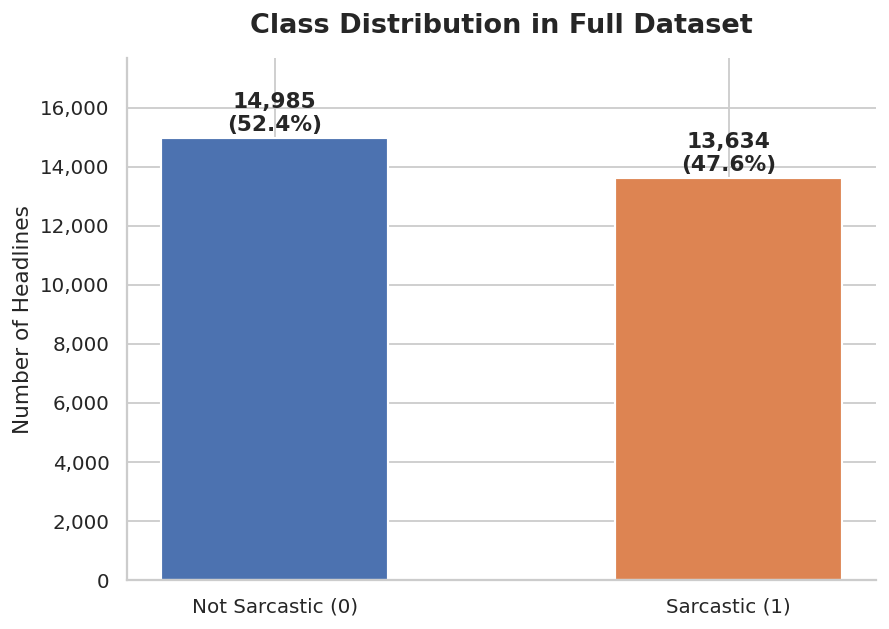

CLASS BALANCE SUMMARY
  Not Sarcastic (0)         14,985  (52.4%)
  Sarcastic (1)             13,634  (47.6%)

  Imbalance ratio:  1.10:1
  Assessment:       Well-balanced


In [ ]:
class_counts = df["is_sarcastic"].value_counts().sort_index()
class_labels = ["Not Sarcastic (0)", "Sarcastic (1)"]
class_pct    = df["is_sarcastic"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    class_labels,
    class_counts,
    color=["#4C72B0", "#DD8452"],
    edgecolor="white",
    linewidth=1.2,
    width=0.5
)
for bar, count, pct in zip(bars, class_counts, class_pct):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{count:,}\n({pct:.1f}%)",
        ha="center", va="bottom",
        fontsize=12, fontweight="bold"
    )

ax.set_title("Class Distribution in Full Dataset", fontsize=15, fontweight="bold", pad=14)
ax.set_ylabel("Number of Headlines", fontsize=12)
ax.set_ylim(0, class_counts.max() * 1.18)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{int(x):,}"))
sns.despine()
plt.tight_layout()
plt.show()

print("=" * 45)
print("CLASS BALANCE SUMMARY")
print("=" * 45)
for label, count, pct in zip(class_labels, class_counts, class_pct):
    print(f"  {label:<25} {count:>6,}  ({pct:.1f}%)")
ratio = class_counts.max() / class_counts.min()
print(f"\n  Imbalance ratio:  {ratio:.2f}:1")
balance_note = "Well-balanced" if ratio < 1.5 else "Moderately imbalanced"
print(f"  Assessment:       {balance_note}")
print("=" * 45)

2. AVERAGE HEADLINE LENGTH

Headline length matters because it directly affects which models are suitable. Very short sequences work well with simple models like Naive Bayes, while longer ones may benefit from sequence-aware models. We measure length in words and tokens — tokens are what the model actually sees after vectorization.


HEADLINE LENGTH STATISTICS

  Characters
    Mean   : 62.3
    Median : 62
    Std    : 20.7
    Min    : 7
    Max    : 926

  Words (whitespace split)
    Mean   : 10.0
    Median : 10
    Std    : 3.4
    Min    : 2
    Max    : 151

  Tokens (TfidfVectorizer)
    Mean   : 10.0
    Median : 10
    Std    : 3.4
    Min    : 2
    Max    : 150


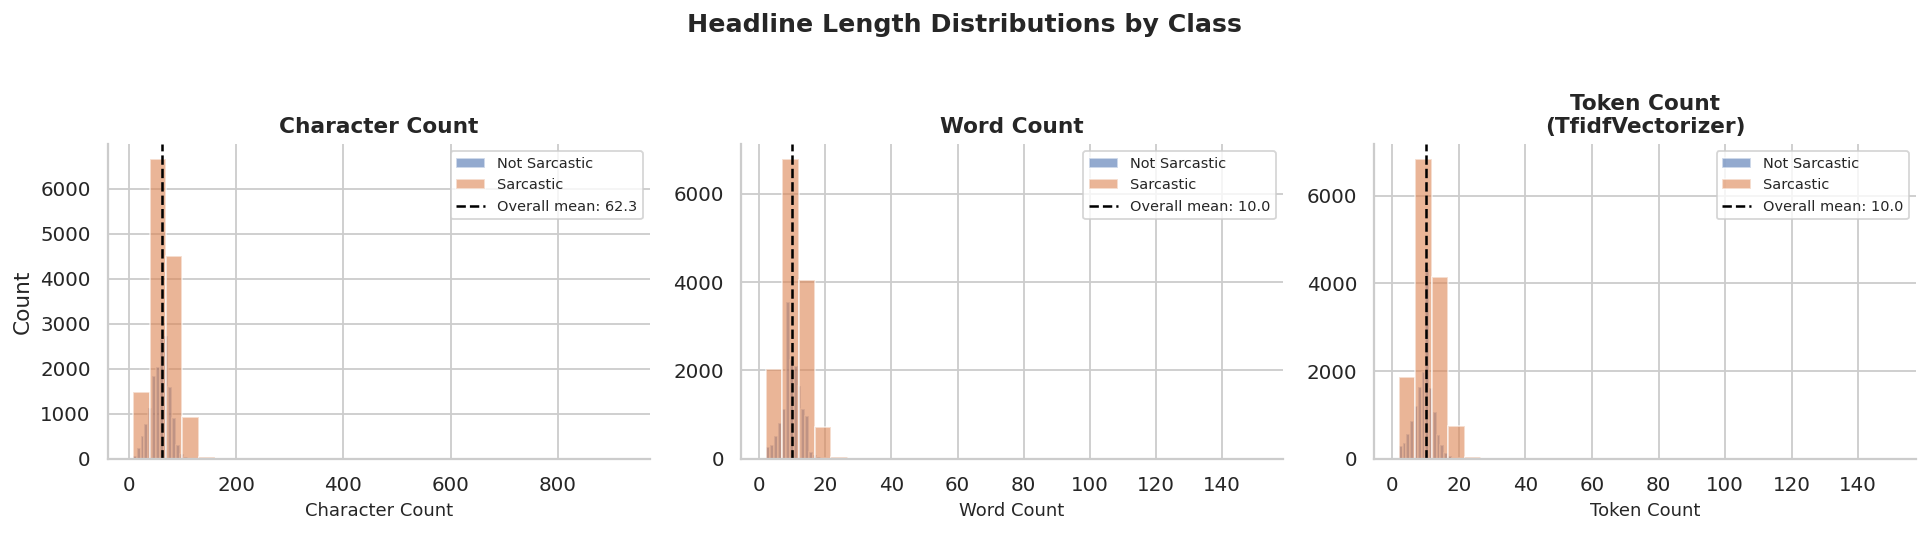


Average token count per class:
is_sarcastic
Not Sarcastic     9.641975
Sarcastic        10.414258


In [ ]:
df["word_count"]  = df["headline"].str.split().str.len()
df["char_count"]  = df["headline"].str.len()
analyzer = count_vect.build_analyzer()
df["token_count"] = df["headline"].apply(lambda h: len(analyzer(h)))

# Summary table
print("\n" + "=" * 55)
print("HEADLINE LENGTH STATISTICS")
print("=" * 55)

for col, label in [("char_count", "Characters"),
                   ("word_count",  "Words (whitespace split)"),
                   ("token_count", "Tokens (TfidfVectorizer)")]:
    print(f"\n  {label}")
    print(f"    Mean   : {df[col].mean():.1f}")
    print(f"    Median : {df[col].median():.0f}")
    print(f"    Std    : {df[col].std():.1f}")
    print(f"    Min    : {df[col].min()}")
    print(f"    Max    : {df[col].max()}")

print("=" * 55)

# Distribution plot — tokens by class
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics = [
    ("char_count",  "Character Count",               "#4C72B0"),
    ("word_count",  "Word Count",                    "#DD8452"),
    ("token_count", "Token Count\n(TfidfVectorizer)", "#55A868"),
]

for ax, (col, title, color) in zip(axes, metrics):
    for sarcasm_val, label, lcolor in [
        (0, "Not Sarcastic", "#4C72B0"),
        (1, "Sarcastic",     "#DD8452"),
    ]:
        subset = df[df["is_sarcastic"] == sarcasm_val][col]
        ax.hist(subset, bins=30, alpha=0.6, label=label, color=lcolor, edgecolor="white")

    mean_val = df[col].mean()
    ax.axvline(mean_val, color="black", linestyle="--", linewidth=1.4,
               label=f"Overall mean: {mean_val:.1f}")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(title.split("\n")[0], fontsize=10)
    ax.set_ylabel("Count" if ax == axes[0] else "")
    ax.legend(fontsize=8)
    sns.despine(ax=ax)

plt.suptitle("Headline Length Distributions by Class", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Average length per class (tokens)
print("\nAverage token count per class:")
print(df.groupby("is_sarcastic")["token_count"].mean().rename({0: "Not Sarcastic", 1: "Sarcastic"}).to_string())

3. MISSING VALUES

Before training, we verify there are no null values in the dataset. Missing headlines or labels would cause errors during vectorization or model training and must be handled before proceeding.

In [ ]:
print("\n" + "=" * 45)
print("MISSING VALUE CHECK")
print("=" * 45)
missing = df[["headline", "is_sarcastic"]].isnull().sum()
for col, val in missing.items():
    status = "✅ None" if val == 0 else f"⚠️  {val} missing"
    print(f"  {col:<20} {status}")
print("=" * 45)



MISSING VALUE CHECK
  headline             ✅ None
  is_sarcastic         ✅ None


 4. WORD CLOUDS

Word clouds give an immediate visual sense of which words dominate each class. The larger the word, the more frequently it appears. This helps us spot early patterns — for example, sarcastic headlines often use exaggerated or dramatic language compared to factual reporting.

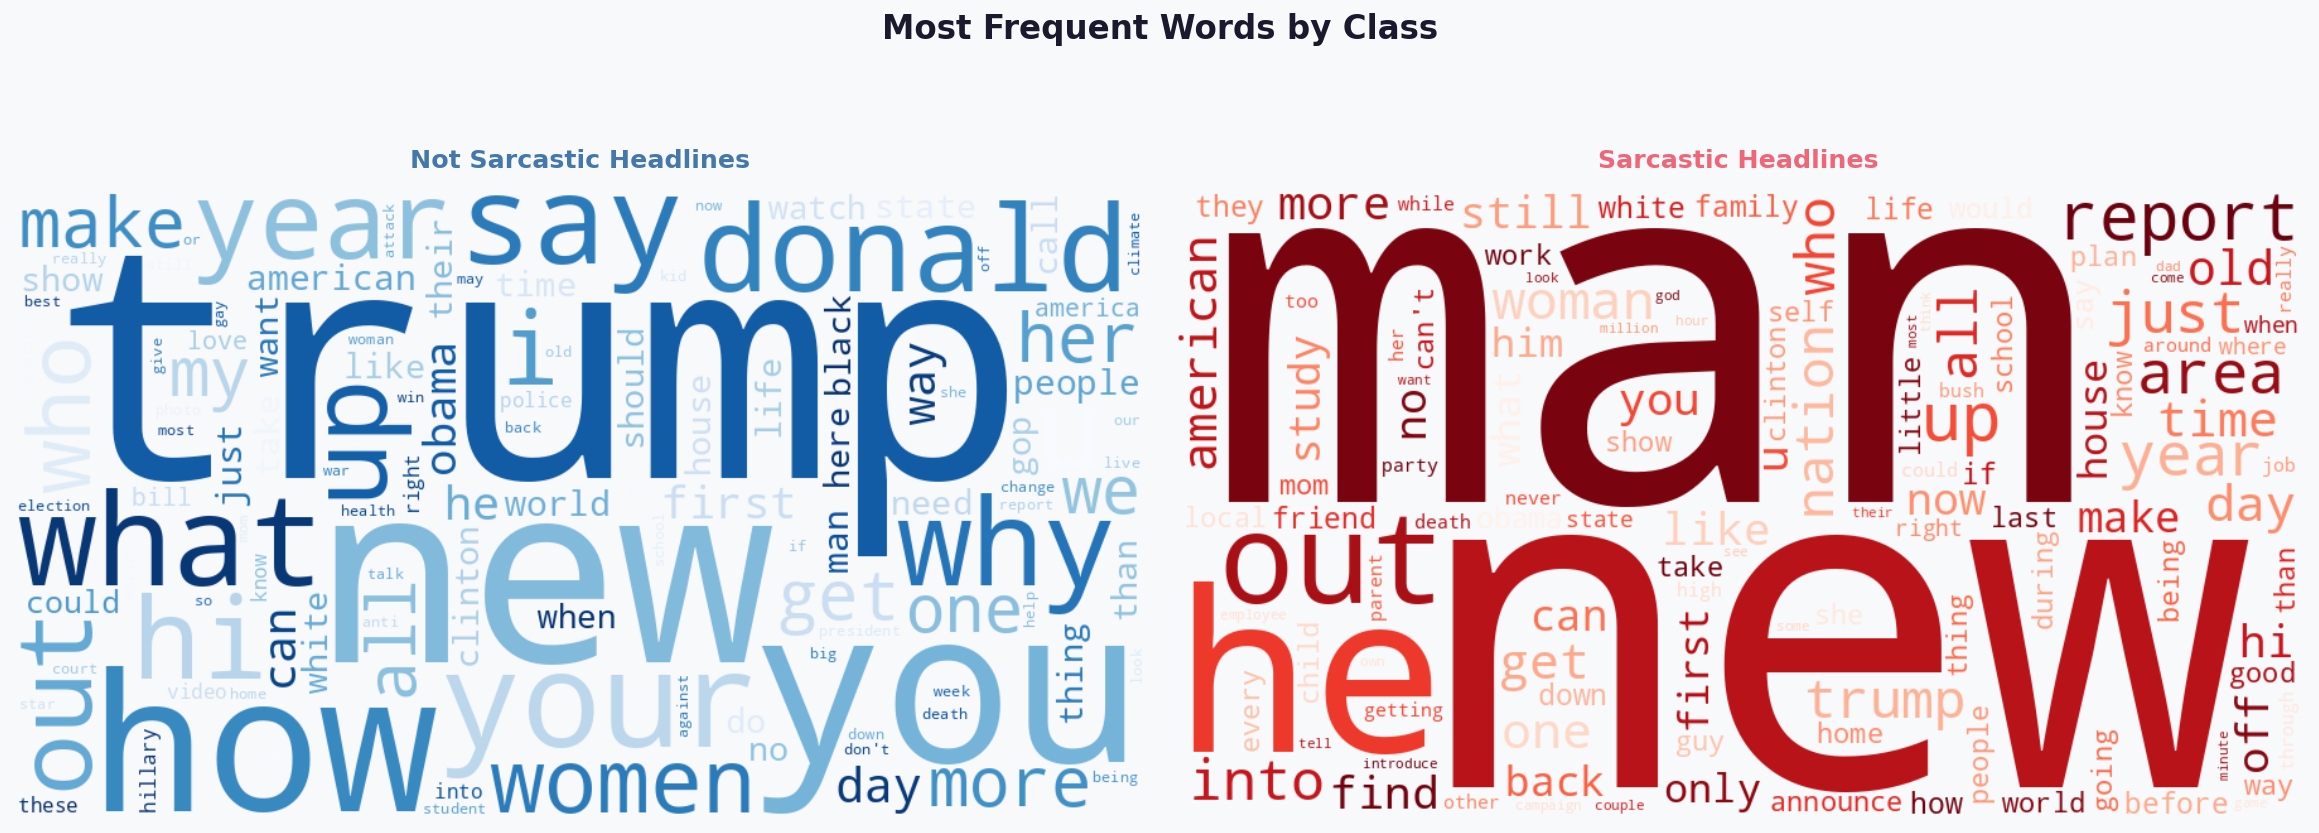

In [ ]:
!pip install wordcloud -q
from wordcloud import WordCloud
import matplotlib.pyplot as plt

BG = "#F8F9FB"
C0 = "#4477AA"
C1 = "#EE6677"

fig, axes = plt.subplots(1, 2, figsize=(18, 7), facecolor=BG)
fig.suptitle(
    "Most Frequent Words by Class",
    fontsize=18, fontweight="bold", color="#1a1a2e", y=1.01
)

configs = [
    (0, "Not Sarcastic Headlines", "Blues",  C0),
    (1, "Sarcastic Headlines",     "Reds",   C1),
]

for ax, (cls, title, cmap, color) in zip(axes, configs):
    text = " ".join(df[df["is_sarcastic"] == cls]["headline"].tolist())
    wc = WordCloud(
        width=900, height=500,
        background_color=BG,
        colormap=cmap,
        max_words=120,
        collocations=False,
        prefer_horizontal=0.85,
        margin=8,
        stopwords={"the","a","an","of","in","to","and","for","is",
                   "on","at","with","as","by","from","that","this",
                   "are","was","were","be","it","its","has","have",
                   "had","will","s","about","after","over","but","not"}
    ).generate(text)

    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_facecolor(BG)
    ax.set_title(title, fontsize=14, fontweight="bold",
                 color=color, pad=12)

plt.tight_layout()
plt.savefig("wordcloud.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()

5. TOP 20 WORDS PER CLASS (side-by-side horizontal bars)

While word clouds are intuitive, they lack precision. This chart ranks the 20 most frequent words in each class with exact counts. Comparing the two lists reveals which words are shared across classes and which are more class-specific — a useful signal for what the model might learn to rely on.

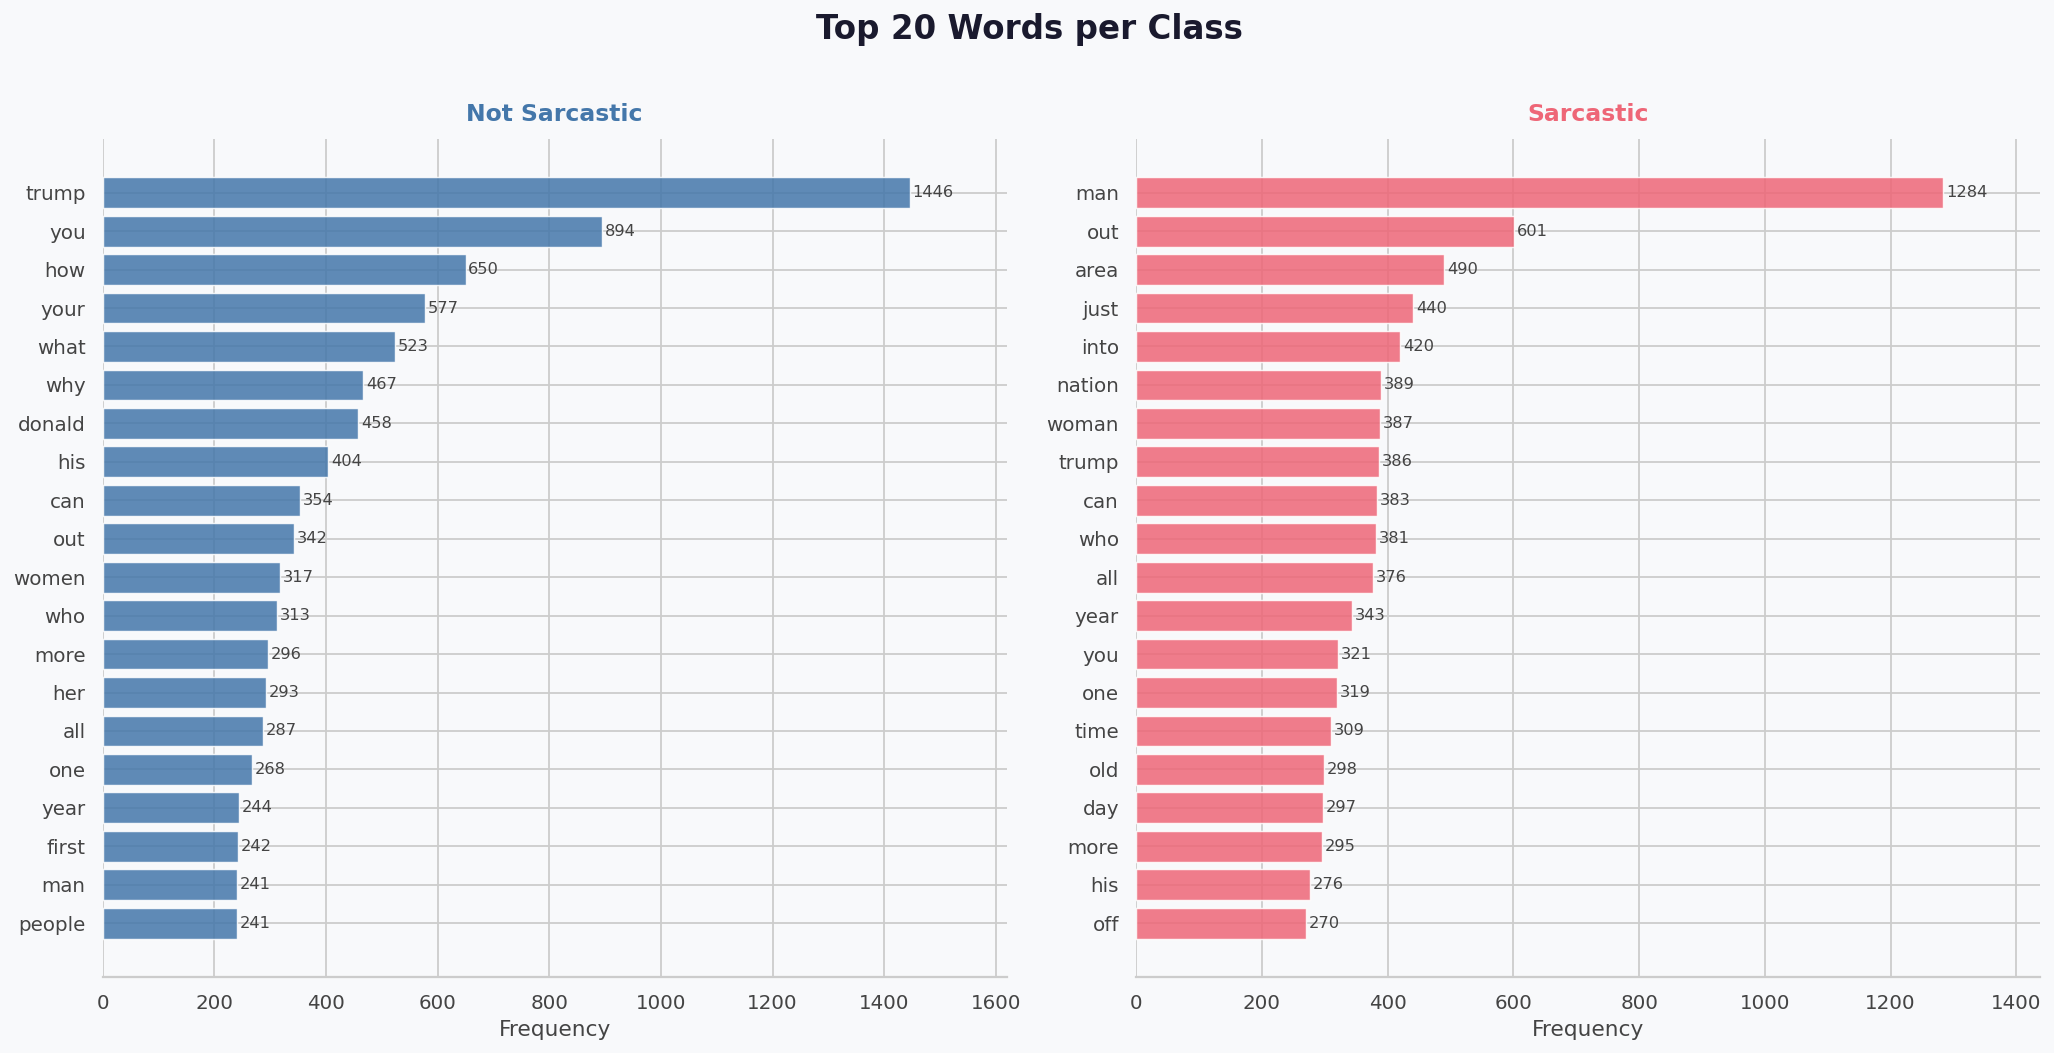

In [ ]:
from collections import Counter
import re

STOPWORDS = {"the","a","an","of","in","to","and","for","is","on","at",
             "with","as","by","from","that","this","are","was","were",
             "be","it","its","has","have","had","will","s","about",
             "after","over","but","not","new","says","report"}

def top_words(series, n=20):
    words = []
    for headline in series:
        tokens = re.findall(r"\b[a-z]{3,}\b", headline.lower())
        words.extend([t for t in tokens if t not in STOPWORDS])
    return Counter(words).most_common(n)

top0 = top_words(df[df["is_sarcastic"] == 0]["headline"])
top1 = top_words(df[df["is_sarcastic"] == 1]["headline"])

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(16, 8), facecolor=BG)
fig.suptitle("Top 20 Words per Class", fontsize=18,
             fontweight="bold", color="#1a1a2e", y=1.01)

for ax, top, color, title in [
    (ax0, top0, C0, "Not Sarcastic"),
    (ax1, top1, C1, "Sarcastic"),
]:
    words_list  = [w for w, _ in reversed(top)]
    counts_list = [c for _, c in reversed(top)]
    bars = ax.barh(words_list, counts_list, color=color,
                   alpha=0.85, edgecolor="white", linewidth=0.8)
    for bar, count in zip(bars, counts_list):
        ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height() / 2,
                str(count), va="center", fontsize=9, color="#444444")
    ax.set_facecolor(BG)
    ax.set_title(title, fontsize=13, fontweight="bold", color=color, pad=10)
    ax.set_xlabel("Frequency", color="#444444")
    ax.spines[["top","right","left"]].set_visible(False)
    ax.spines["bottom"].set_color("#cccccc")
    ax.tick_params(colors="#444444", left=False)
    ax.set_xlim(0, counts_list[-1] * 1.12)

plt.tight_layout()
plt.savefig("top_words.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()

6. VIOLIN PLOT (token length by class)

The violin plot extends a standard box plot by showing the full shape of the distribution. A wider section means more headlines have that token length. This tells us whether the average is a reliable summary or whether the data is skewed or has two peaks (bimodal), which a single mean would hide.

/tmp/ipykernel_754/1281489057.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


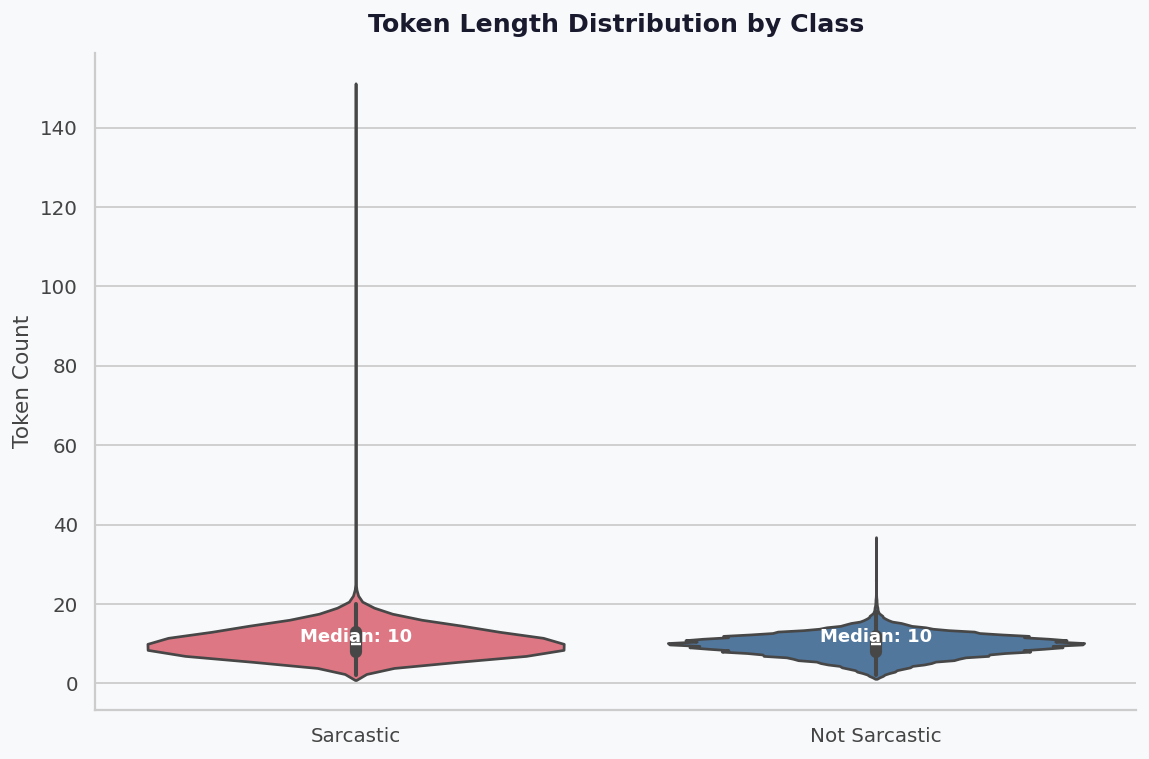

In [ ]:
import seaborn as sns

plot_df = df[["is_sarcastic", "token_count"]].copy()
plot_df["Class"] = plot_df["is_sarcastic"].map({0: "Not Sarcastic", 1: "Sarcastic"})

fig, ax = plt.subplots(figsize=(9, 6), facecolor=BG)
ax.set_facecolor(BG)

sns.violinplot(
    data=plot_df,
    x="Class",
    y="token_count",
    palette={"Not Sarcastic": C0, "Sarcastic": C1},
    inner="box",
    linewidth=1.5,
    ax=ax
)


for i, cls in enumerate([0, 1]):
    med = df[df["is_sarcastic"] == cls]["token_count"].median()
    ax.text(i, med + 0.4, f"Median: {med:.0f}",
            ha="center", fontsize=10, fontweight="bold", color="white")

ax.set_title("Token Length Distribution by Class",
             fontsize=14, fontweight="bold", color="#1a1a2e", pad=12)
ax.set_ylabel("Token Count", color="#444444")
ax.set_xlabel("")
ax.spines[["top","right"]].set_visible(False)
ax.spines[["left","bottom"]].set_color("#cccccc")
ax.tick_params(colors="#444444")

plt.tight_layout()
plt.savefig("violin.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


7. 3D BAR CHART (class × avg token length)

This 3D chart brings together two key metrics — class size and average token length — into a single view. It serves as a compact visual summary of the dataset before moving into modelling.

/tmp/ipykernel_754/2634927327.py:53: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


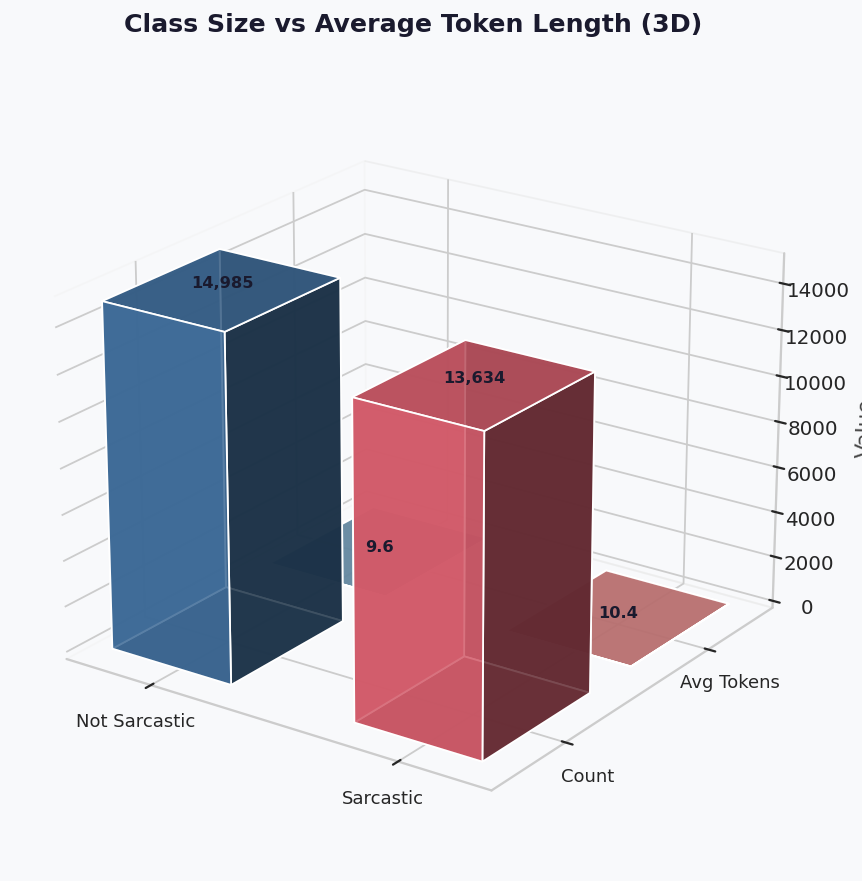

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8), facecolor=BG)
ax  = fig.add_subplot(111, projection="3d")
ax.set_facecolor(BG)
fig.patch.set_facecolor(BG)

xpos      = [0, 1]
ypos      = [0, 0]
zpos      = [0, 0]
dx = dy   = [0.5, 0.5]

# Bar 1: class counts (left axis)
dz_count  = [int(class_counts[0]), int(class_counts[1])]
# Bar 2: avg token length (shifted on y)
dz_tokens = [
    df[df["is_sarcastic"] == 0]["token_count"].mean(),
    df[df["is_sarcastic"] == 1]["token_count"].mean(),
]

colors_count  = [C0, C1]
colors_tokens = ["#88BBDD", "#FF9999"]

# Count bars
ax.bar3d([0, 1], [0, 0], [0, 0], dx, dy,
         dz_count, color=colors_count, alpha=0.85, shade=True)

# Token avg bars — shifted in Y
ax.bar3d([0, 1], [0.7, 0.7], [0, 0], dx, dy,
         dz_tokens, color=colors_tokens, alpha=0.75, shade=True)

# Labels on top of bars
for xi, zi_c, zi_t in zip([0.25, 1.25], dz_count, dz_tokens):
    ax.text(xi, 0.25, zi_c + 100, f"{zi_c:,}", color="#1a1a2e",
            fontsize=9, fontweight="bold", ha="center")
    ax.text(xi, 0.95, zi_t + 0.3, f"{zi_t:.1f}", color="#1a1a2e",
            fontsize=9, fontweight="bold", ha="center")

ax.set_xticks([0.25, 1.25])
ax.set_xticklabels(["Not Sarcastic", "Sarcastic"], fontsize=10)
ax.set_yticks([0.25, 0.95])
ax.set_yticklabels(["Count", "Avg Tokens"], fontsize=10)
ax.set_zlabel("Value", labelpad=8, color="#444444")
ax.set_title("Class Size vs Average Token Length (3D)",
             fontsize=14, fontweight="bold", color="#1a1a2e", pad=20)

ax.view_init(elev=22, azim=-55)
ax.grid(True, color="#dddddd", linewidth=0.5)
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

plt.tight_layout()
plt.savefig("3d_chart.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()

#BASELINE MODEL - Logistic Regression

BASELINE — LOGISTIC REGRESSION RESULTS
  Accuracy  : 0.8438  (84.38%)
  Precision : 0.8292
  Recall    : 0.8491
  F1 Score  : 0.8390


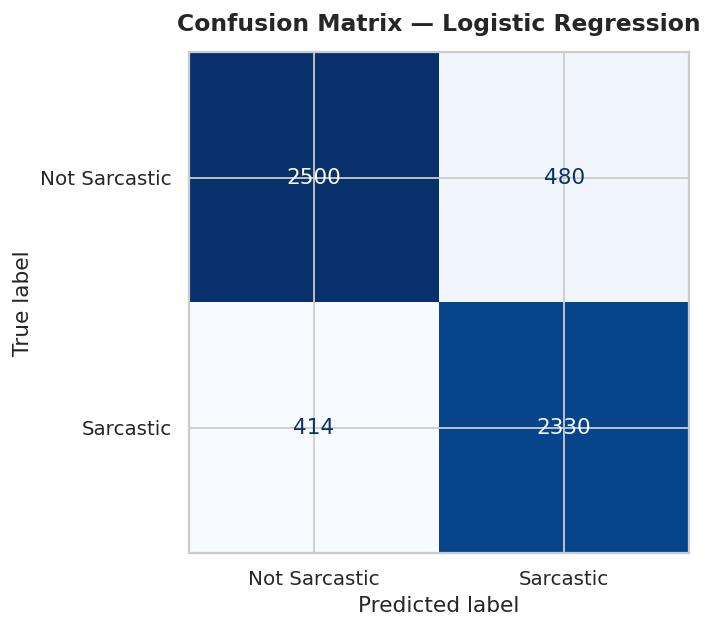

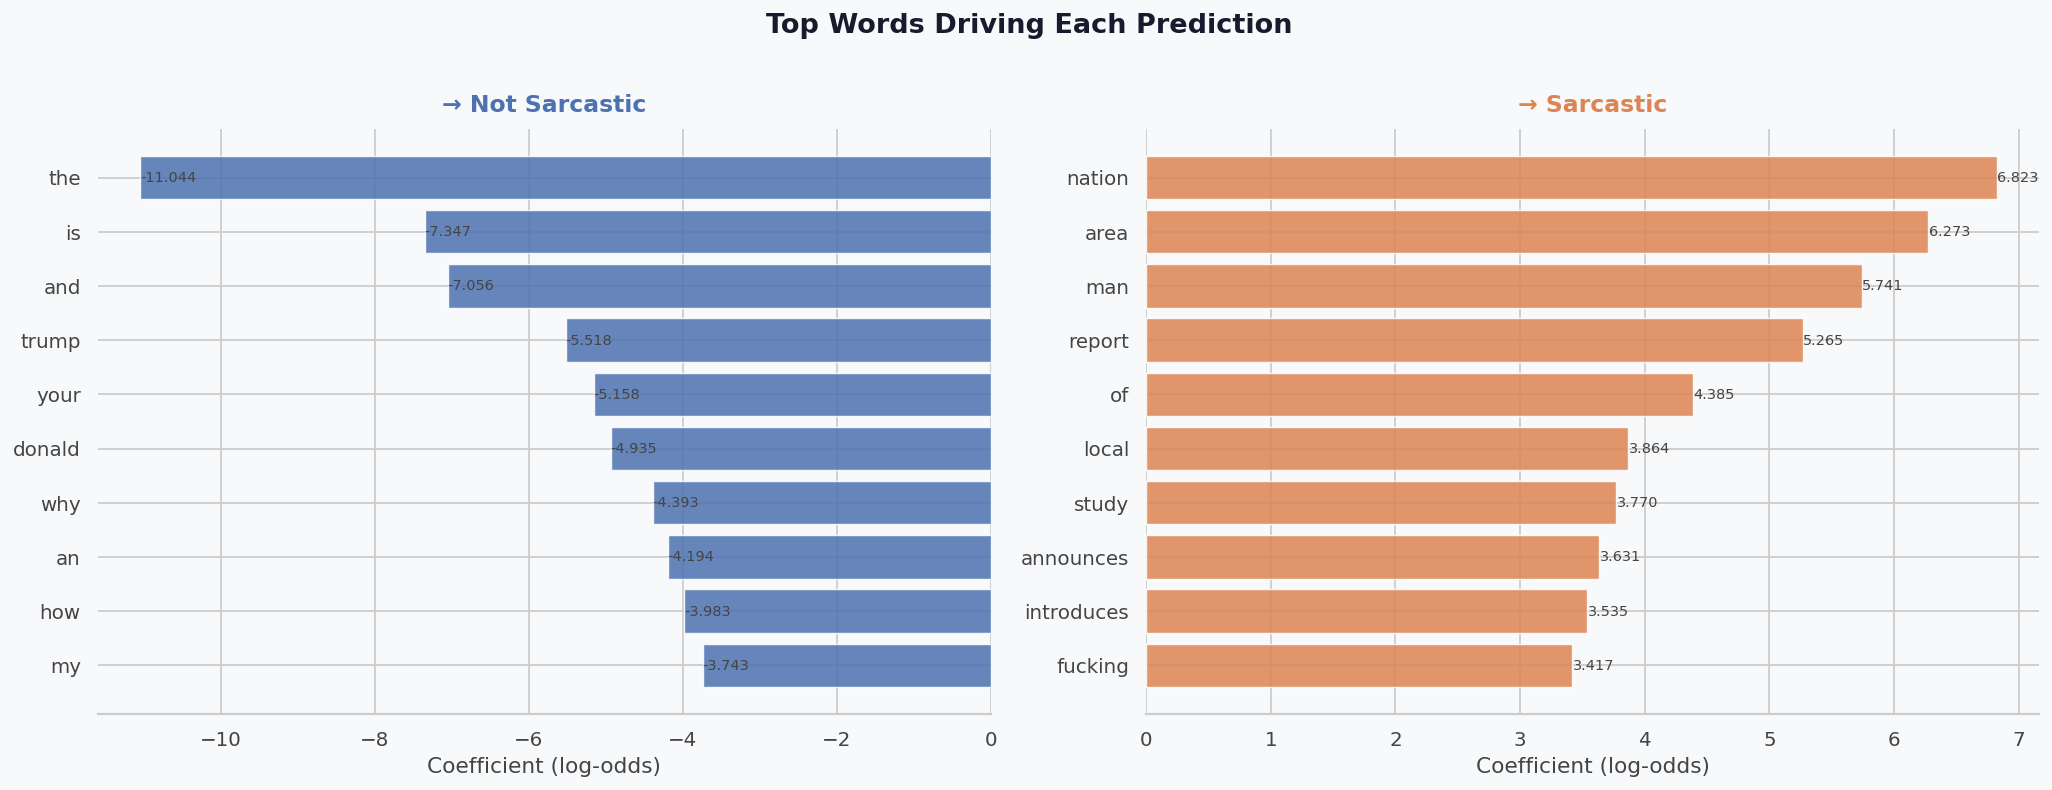

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             ConfusionMatrixDisplay, confusion_matrix)
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Train ---
lr_model = LogisticRegression(max_iter=1000, random_state=66)
lr_model.fit(x_training_vec, y_training)

# --- 2. Predict ---
y_pred = lr_model.predict(x_test_vec)

# --- 3. Evaluation Metrics ---
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)

print("=" * 45)
print("BASELINE — LOGISTIC REGRESSION RESULTS")
print("=" * 45)
print(f"  Accuracy  : {acc:.4f}  ({acc*100:.2f}%)")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1 Score  : {f1:.4f}")
print("=" * 45)

# --- 4. Confusion Matrix ---
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=["Not Sarcastic", "Sarcastic"])
disp.plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Confusion Matrix — Logistic Regression",
             fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# --- 5. Top Predictive Words (Coefficients) ---
feature_names = count_vect.get_feature_names_out()
coefficients  = lr_model.coef_[0]
top_n = 10

top_sarcastic     = np.argsort(coefficients)[-top_n:][::-1]   # highest coef → sarcastic
top_not_sarcastic = np.argsort(coefficients)[:top_n]          # lowest coef  → not sarcastic

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), facecolor="#F8F9FB")
fig.suptitle("Top Words Driving Each Prediction",
             fontsize=15, fontweight="bold", color="#1a1a2e", y=1.01)

for ax, indices, color, title in [
    (ax1, top_not_sarcastic, "#4C72B0", "→ Not Sarcastic"),
    (ax2, top_sarcastic,     "#DD8452", "→ Sarcastic"),
]:
    words  = [feature_names[i] for i in indices][::-1]
    scores = [coefficients[i]  for i in indices][::-1]
    bars = ax.barh(words, scores, color=color, alpha=0.85,
                   edgecolor="white", linewidth=0.8)
    for bar, score in zip(bars, scores):
        ax.text(score + (0.005 if score > 0 else -0.005),
                bar.get_y() + bar.get_height() / 2,
                f"{score:.3f}", va="center", fontsize=8, color="#444444")
    ax.set_facecolor("#F8F9FB")
    ax.set_title(title, fontsize=13, fontweight="bold", color=color, pad=10)
    ax.set_xlabel("Coefficient (log-odds)", color="#444444")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#cccccc")
    ax.tick_params(colors="#444444", left=False)

plt.tight_layout()
plt.savefig("top_coefficients.png", dpi=150, bbox_inches="tight", facecolor="#F8F9FB")
plt.show()

#MAIN MODEL - BERT + LOGISTIC REGRESSION

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Using device: cuda

Generating BERT embeddings for training data...


100%|██████████| 716/716 [00:44<00:00, 16.18it/s]



Generating BERT embeddings for test data...


100%|██████████| 179/179 [00:10<00:00, 16.54it/s]



Embedding shape:
(22895, 768)
BERT EMBEDDINGS + LOGISTIC REGRESSION
Accuracy  : 0.8627 (86.27%)
Precision : 0.8557
Recall    : 0.8582
F1 Score  : 0.8570


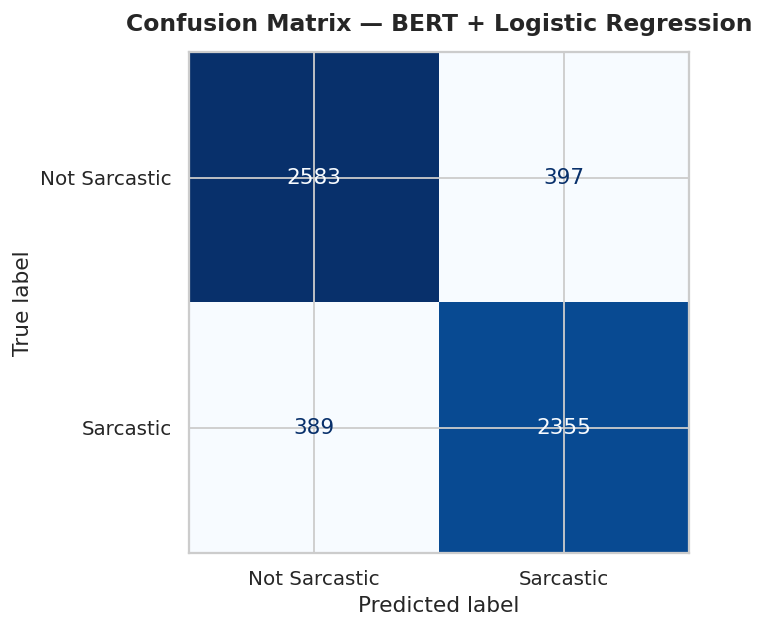

In [ ]:
import torch
from transformers import BertTokenizer, BertModel
from tqdm import tqdm

# --- 1. Load BERT ---
MODEL_NAME = "bert-base-uncased"

tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)
bert_model = BertModel.from_pretrained(MODEL_NAME)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model.to(device)

bert_model.eval()

print(f"Using device: {device}")

# --- 2. BERT embeddings
def generate_embeddings(texts, batch_size=32, max_length=64):

    embeddings = []

    for i in tqdm(range(0, len(texts), batch_size)):

        batch_texts = texts[i:i + batch_size]

        encoded = tokenizer(
            batch_texts.tolist(),
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)

        with torch.no_grad():

            outputs = bert_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # CLS token embedding
            cls_embeddings = outputs.last_hidden_state[:, 0, :]

            embeddings.append(cls_embeddings.cpu().numpy())

    return np.vstack(embeddings)

print("\nGenerating BERT embeddings for training data...")
x_train_bert = generate_embeddings(x_training)

print("\nGenerating BERT embeddings for test data...")
x_test_bert = generate_embeddings(x_test)

print("\nEmbedding shape:")
print(x_train_bert.shape)  # dimension of the embeddings (should be 768(bert_base))

# --- 3. Logistic Regression Training (it is classifier!)

bert_lr_model = LogisticRegression(
    max_iter=2000,
    random_state=66
)

bert_lr_model.fit(x_train_bert, y_training)

# --- 4. Predictions and Evaluation

y_pred_bert = bert_lr_model.predict(x_test_bert)

acc  = accuracy_score(y_test, y_pred_bert)
prec = precision_score(y_test, y_pred_bert)
rec  = recall_score(y_test, y_pred_bert)
f1   = f1_score(y_test, y_pred_bert)

print("=" * 50)
print("BERT EMBEDDINGS + LOGISTIC REGRESSION")
print("=" * 50)
print(f"Accuracy  : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1 Score  : {f1:.4f}")
print("=" * 50)

# --- 5. Confusion Matrix ---

fig, ax = plt.subplots(figsize=(6, 5))

cm = confusion_matrix(y_test, y_pred_bert)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Sarcastic", "Sarcastic"]
)

disp.plot(ax=ax, colorbar=False, cmap="Blues")

ax.set_title(
    "Confusion Matrix — BERT + Logistic Regression",
    fontsize=13,
    fontweight="bold",
    pad=12
)

plt.tight_layout()
plt.show()

#Model Fine-Tuning

In [ ]:
import sys
# Remove torchvision from sys.modules so datasets won't try to import VideoReader from it
mods_to_remove = [key for key in sys.modules if "torchvision" in key]
for mod in mods_to_remove:
    del sys.modules[mod]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss


FINE-TUNED BERT RESULTS
  Accuracy  : 0.8900  (89.00%)
  Precision : 0.9090
  Recall    : 0.8582
  F1 Score  : 0.8829


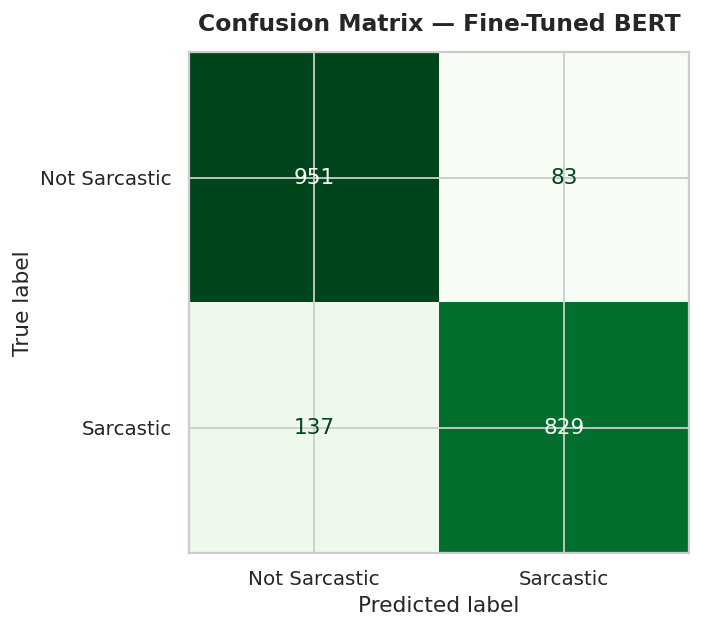

Saved: confusion_matrix_finetuned.png


In [ ]:
import torch
import pandas as pd


from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
from datasets import Dataset

#--- 1. Transfer Data
train_texts = x_training.tolist()[:8000] # [:8000] = we only use first 8000 samples to reduce training time # speed optimization
test_texts = x_test.tolist()[:2000] # Only 2000 test samples used # speed optimization

train_labels = y_training.tolist()[:8000]
test_labels = y_test.tolist()[:2000]

#--- 2. Create Hugging Face Dataset

train_dataset = Dataset.from_pandas(pd.DataFrame({
    "text": train_texts,
    "label": train_labels
}))

test_dataset = Dataset.from_pandas(pd.DataFrame({
    "text": test_texts,
    "label": test_labels
}))

#--- 3. Load BERT Tokenizer

MODEL_NAME = "bert-base-uncased"
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

#--- 4. Tokenization function

def tokenize_function(example):
    return tokenizer(
        example["text"],
        padding="max_length", # Forces all sequences to same length
        truncation=True, # Cuts sentences longer than max_length
        max_length=32 # Maximum number of tokens per sentence# only 32: speed optimization
    )

#--- 5. Apply tokenization

train_dataset = train_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

#--- 6. Remove raw text column

train_dataset = train_dataset.remove_columns(["text"])
test_dataset = test_dataset.remove_columns(["text"])

#--- 7. Converts dataset into PyTorch tensors

train_dataset.set_format("torch")
test_dataset.set_format("torch")


#--- 8. Load BERT model for classification

model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

#--- 9. Data Collator

data_collator = DataCollatorWithPadding(tokenizer=tokenizer) #ensures that all sentences within a batch have the same length


#--- 10. Training configuration

training_args = TrainingArguments(
    output_dir="./results", # Where model checkpoints are saved
    num_train_epochs=1, # How many times model sees the full dataset # speed optimization
    per_device_train_batch_size=32, # Number of samples processed at once
    per_device_eval_batch_size=32, # Same batch size for evaluation
    eval_strategy="no", # disabled evaluation during training # sped optimization
    save_strategy="no", # disabled model saving checkpoints #speed optimization
    logging_steps=1000, # Prints training logs every 1000 steps #speed optimization
    learning_rate=2e-5, # How fast model learns
    weight_decay=0.01, # Regularization to prevent overfitting
    fp16=True, # Mixed precision training #speed optimization
    report_to="none" # no external logging tools
)

#--- 11. Create Trainer

trainer = Trainer(
    model=model, # BERT model to be trained
    args=training_args, # Training configuration
    train_dataset=train_dataset, # Data used for learning
    eval_dataset=test_dataset, # Data used for evaluation
    data_collator=data_collator # Handles dynamic padding efficiently
)

#--- 12. Start training (fine-tuning)

trainer.train()

#--- 13. Evaluation

pred_output = trainer.predict(test_dataset)
y_pred = np.argmax(pred_output.predictions, axis=1)

acc  = accuracy_score(test_labels, y_pred)
prec = precision_score(test_labels, y_pred)
rec  = recall_score(test_labels, y_pred)
f1   = f1_score(test_labels, y_pred)

print("=" * 50)
print("FINE-TUNED BERT RESULTS")
print("=" * 50)
print(f"  Accuracy  : {acc:.4f}  ({acc*100:.2f}%)")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1 Score  : {f1:.4f}")
print("=" * 50)

# Confusion Matrix — Fine-Tuned BERT
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(test_labels, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Sarcastic", "Sarcastic"]
)
disp.plot(ax=ax, colorbar=False, cmap="Greens")
ax.set_title("Confusion Matrix — Fine-Tuned BERT",
             fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("confusion_matrix_finetuned.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: confusion_matrix_finetuned.png")



In [ ]:

import pandas as pd
import os
from transformers import BertTokenizer
import kagglehub
path = kagglehub.dataset_download("rmisra/news-headlines-dataset-for-sarcasm-detection")
df = pd.read_json(os.path.join(path, "Sarcasm_Headlines_Dataset_v2.json"), lines=True)
print("Path to dataset files:", path)

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert_lengths = df["headline"].apply(lambda h: len(tokenizer.encode(h, add_special_tokens=True)))

print(f"Mean BERT token length: {bert_lengths.mean():.1f}")

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

bert_lengths = df["headline"].apply(
    lambda h: len(tokenizer.encode(h, add_special_tokens=True))  # includes [CLS] and [SEP]
)

print("BERT Token Length Statistics")
print(f"  Mean   : {bert_lengths.mean():.1f}")
print(f"  Median : {bert_lengths.median():.0f}")
print(f"  Std    : {bert_lengths.std():.1f}")
print(f"  Max    : {bert_lengths.max()}")
print(f"\n  % covered by max_length=32 : {(bert_lengths <= 32).mean()*100:.1f}%")
print(f"  % covered by max_length=48 : {(bert_lengths <= 48).mean()*100:.1f}%")
print(f"  % covered by max_length=64 : {(bert_lengths <= 64).mean()*100:.1f}%")

Using Colab cache for faster access to the 'news-headlines-dataset-for-sarcasm-detection' dataset.
Path to dataset files: /kaggle/input/news-headlines-dataset-for-sarcasm-detection
Mean BERT token length: 14.8
BERT Token Length Statistics
  Mean   : 14.8
  Median : 14
  Std    : 4.5
  Max    : 193

  % covered by max_length=32 : 99.9%
  % covered by max_length=48 : 100.0%
  % covered by max_length=64 : 100.0%


#Model Comparison

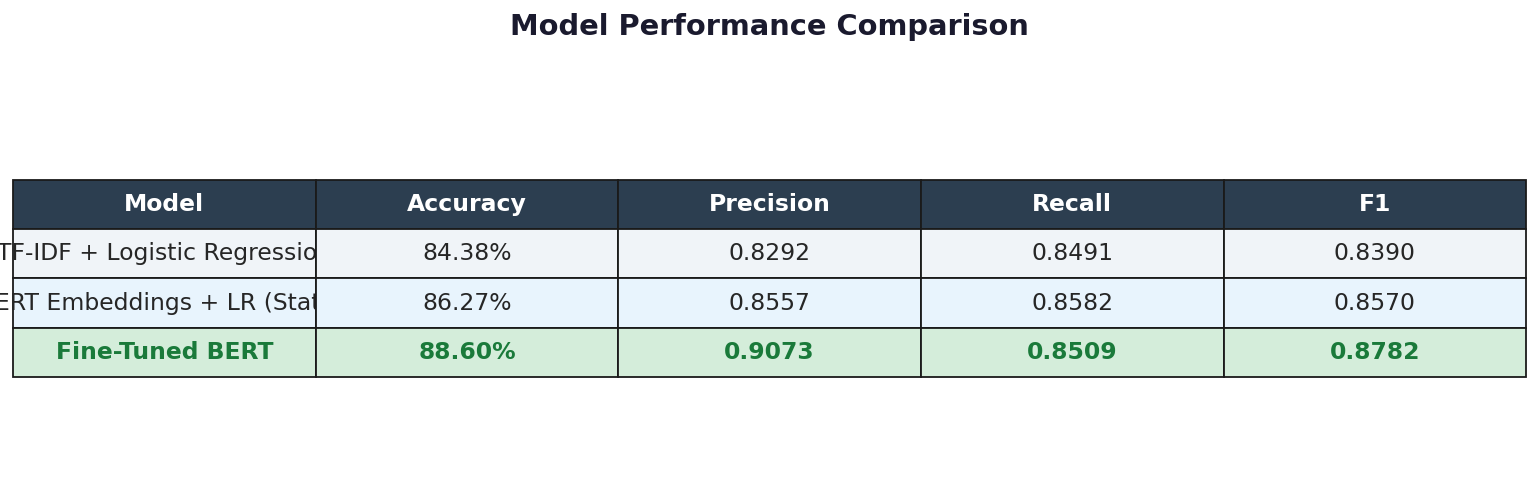

Saved: performance_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 4))
ax.axis('off')

# Data
columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1']
rows = [
    ['TF-IDF + Logistic Regression', '84.38%', '0.8292', '0.8491', '0.8390'],
    ['BERT Embeddings + LR (Static)', '86.27%', '0.8557', '0.8582', '0.8570'],
    ['Fine-Tuned BERT',               '88.60%', '0.9073', '0.8509', '0.8782'],
]

colors = [
    ['#f0f4f8', '#f0f4f8', '#f0f4f8', '#f0f4f8', '#f0f4f8'],
    ['#e8f4fd', '#e8f4fd', '#e8f4fd', '#e8f4fd', '#e8f4fd'],
    ['#d4edda', '#d4edda', '#d4edda', '#d4edda', '#d4edda'],
]

table = ax.table(
    cellText=rows,
    colLabels=columns,
    cellLoc='center',
    loc='center',
    cellColours=colors
)

table.auto_set_font_size(False)
table.set_fontsize(13)
table.scale(1, 2.2)

# Header styling
for j in range(len(columns)):
    table[0, j].set_facecolor('#2c3e50')
    table[0, j].set_text_props(color='white', fontweight='bold')

# Bold + green za Fine-Tuned BERT cijeli red
for j in range(len(columns)):
    table[3, j].set_text_props(fontweight='bold', color='#1a7a3a')

ax.set_title('Model Performance Comparison', fontsize=16, fontweight='bold', pad=20, color='#1a1a2e')

plt.tight_layout()
plt.savefig('performance_comparison.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: performance_comparison.png")